In [1]:
import os, sys
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
from numpy import amin,amax
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy, copy
from scipy import interpolate
from importlib import reload
import json, glob, time
from tqdm.auto import tqdm

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.pyplot import cm

In [3]:
from torch.utils.data import DataLoader
from torch.utils.data import DataLoader
import torch.nn.functional as F

In [4]:
from scipy.spatial.distance import pdist, squareform
from scipy.spatial import distance_matrix

In [5]:
# Setting matplotlib params for aesthetic plots
#%matplotlib widget
%matplotlib inline
plt.rcParams["figure.figsize"] = (5, 3)
plt.rcParams["axes.grid"]=True;plt.rcParams["grid.alpha"]=0.4; 
plt.rcParams["grid.color"]='#999999'; plt.rcParams["grid.linestyle"]='--'

In [6]:
def build_mlp(input_dim, hidden_dim, output_dim, layers, activation=nn.GELU()):
    """Create an MLP from the configuration."""
    seq = [nn.Linear(input_dim, hidden_dim), activation]
    for _ in range(layers):
        seq += [nn.Linear(hidden_dim, hidden_dim), activation]
    seq += [nn.Linear(hidden_dim, output_dim)]
    return nn.Sequential(*seq)

In [7]:
folder ="./"
ca_SubBanks=[]
phases_SubBanks=[]
SVD_SubBanks=[]
nbanks=1
subbanks=[3]

In [8]:
weights_banks=[]
ndims=10

In [9]:
bank_name=1
for ib in range(nbanks):
    print("$$$$$$$$$$$$$$$")
    print(bank_name)
    print("###############")
    wts=np.loadtxt(folder+"weights_"+str(bank_name)+".txt")
    weights_banks.append(wts)
    print(wts.shape)
    _=[]
    __=[]
    ___=[]
    sub_bank_name=0
    #for isb in range(subbanks[ib]):
    for isb in range(1):
        #--> test only b_1_sb_0...
        print(isb)
        name=str(bank_name)
        subname = str(sub_bank_name)
        #print(name,subname)
        #ca=np.loadtxt(folder+"ca_bank_"+name+"_subbank_"+subname+"-first_10.txt")
        #print(ca.shape)
        #np.random.seed(1618)
        #ind_=np.random.choice([0, 1], size=(len(ca),), p=[0.9, 0.1]).astype('bool')
        #np.savetxt(folder+"ca_bank_"+name+"_subbank_"+subname+"-first_10_only_10_percent.txt",ca[ind_,:])
        ca=np.loadtxt(folder+"ca_bank_"+name+"_subbank_"+subname+"-first_10_only_10_percent.txt")
        print(ca.shape)
        #phases=np.loadtxt(folder+"phases_bank_"+name+"_subbank_"+subname+".txt")
        #print(phases.shape)
        #np.savetxt(folder+"phases_bank_"+name+"_subbank_"+subname+"-first_10_only_10_percent.txt",phases[ind_,:])
        phases=np.loadtxt(folder+"phases_bank_"+name+"_subbank_"+subname+"-first_10_only_10_percent.txt")
        print(phases.shape)
        Vph=np.loadtxt(folder+"Vph_bank_"+name+"_subbank_"+subname+"-first_10.txt")
        print(Vph.shape)
        mean_phase=np.loadtxt(folder+"mean_phase_bank_"+name+"_subbank_"+subname+".txt")
        print(mean_phase.shape)
        _.append(ca)
        __.append(phases)
        ___.append([Vph, Vph, Vph, mean_phase])
        #--> Vph, Vph, Vph because before I was importing also Up, sp, Vph and I didn't want to look for everywhere I had to change the code...
        sub_bank_name = sub_bank_name+1
    ca_SubBanks.append(_)
    phases_SubBanks.append(__)
    SVD_SubBanks.append(___)
    bank_name = bank_name+1

$$$$$$$$$$$$$$$
1
###############
(1000,)
0
(888, 10)
(888, 1000)
(10, 1000)
(1000,)


In [10]:
bank_name=1

In [11]:
#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    print(ca_SubBanks[0][i].shape)
    print(phases_SubBanks[0][i].shape)
    print(SVD_SubBanks[0][i][2].shape)
    print(SVD_SubBanks[0][i][3].shape)
    print("#################################")

(888, 10)
(888, 1000)
(10, 1000)
(1000,)
#################################


In [12]:
ca_phases_Vph_mean_phase=[]
#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    ca_phases_Vph_mean_phase.append([ca_SubBanks[0][i],
                                     phases_SubBanks[0][i],
                                     SVD_SubBanks[0][i][2],
                                     SVD_SubBanks[0][i][3]])

In [13]:
weights=weights_banks[0]
#--> this depends only on bank, not subbank...
wt=weights#**0.5

In [14]:
#--> recall that ind selects validation, ~ind selects training...
#train_data = data[~ind]
#valid_data = data[ind]

In [15]:
dims = 10
data=[]
norm_factor=[]
train_data=[]
valid_data=[]
ind=[]

In [16]:
folder_pth = "./"

In [17]:
sub_bank_name=0
#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    ca=ca_phases_Vph_mean_phase[i][0]
    ca_ = torch.tensor(ca[:, :dims], dtype=torch.float32)
    #norm_factor_ = torch.std(ca_[:,0])
    norm_factor__=np.loadtxt(folder_pth+"norm_factor_b_"+str(bank_name)+"_sb_"+str(sub_bank_name)+".txt")
    #print(norm_factor_.numpy(), norm_factor__)
    norm_factor_=torch.tensor(norm_factor__, dtype=torch.float32)
    print(norm_factor_.numpy(), norm_factor__)
    ca_ = ca_/norm_factor_
    data.append(ca_)
    norm_factor.append(norm_factor_)
    np.random.seed(1648)
    ind_=np.random.choice([0, 1], size=(len(ca),), p=[1./2, 1./2]).astype('bool')
    train_data.append(ca_[~ind_])
    valid_data.append(ca_[ind_])
    ind.append(ind_)
    sub_bank_name = sub_bank_name+1

11.944834 11.944833755493164


In [18]:
def build_mlp(input_dim, hidden_dim, output_dim, layers, activation=nn.GELU()):
    """Create an MLP from the configuration."""
    seq = [nn.Linear(input_dim, hidden_dim), activation]
    for _ in range(layers):
        seq += [nn.Linear(hidden_dim, hidden_dim), activation]
    seq += [nn.Linear(hidden_dim, output_dim)]
    return nn.Sequential(*seq)

In [19]:
# Define the Autoencoder model
class Autoencoder_suppress(nn.Module):
    def __init__(self, input_dim=10, hidden_dim=64, latent_dim=2, layers=4):
        super(Autoencoder_suppress, self).__init__()
        # Encoder
        self.encoder = build_mlp(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=latent_dim, layers=layers)
        # Decoder
        self.decoder = build_mlp(input_dim=latent_dim, hidden_dim=hidden_dim, output_dim=input_dim, layers=layers)

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded, encoded

In [20]:
def upper_tri_masking(A):
    m = A.shape[0]
    r = np.arange(m)
    mask = r[:,None] < r
    return A[mask], mask

In [21]:
auto_list=[]
for i in range(subbanks[0]):
    autoencoder_i = Autoencoder_suppress(input_dim=dims, hidden_dim=64, latent_dim=2, layers=4)
    autoencoder_i.load_state_dict(torch.load(folder_pth + 'autoencoder_b_'+str(bank_name)+'_sb_'+str(i)+'.pth', map_location='cpu'))
    autoencoder_i.eval()
    auto_list.append(autoencoder_i)

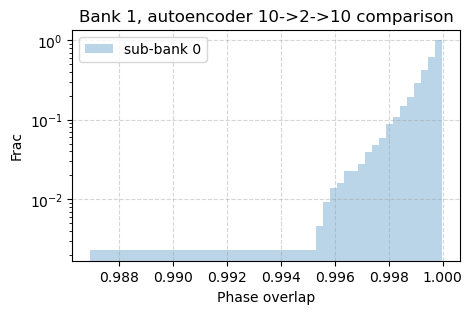

In [22]:
cos_exp_f2_AE_list = []

#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    autoencoder_i = auto_list[i]
    valid_data_i = valid_data[i]
    ind_i=ind[i]
    phases=ca_phases_Vph_mean_phase[i][1]
    Vph=ca_phases_Vph_mean_phase[i][2]
    mean_phase=ca_phases_Vph_mean_phase[i][3]
    
    ca_autoencoder = autoencoder_i(valid_data_i[:, :dims])[0] * norm_factor[i]
    ca_autoencoder = ca_autoencoder.detach().numpy()
    phases_f = ca_autoencoder @ Vph[:dims, :] + mean_phase
    cos_exp_f2_AE = np.real(np.einsum('ij,ij -> i', np.exp(1j * phases_f / wt) * wt, np.conj(np.exp(1j * phases[ind_i] / wt) * wt)))
    cos_exp_f2_AE_list.append(cos_exp_f2_AE)

plt.hist(cos_exp_f2_AE_list[0], log=True, bins=50, cumulative=True, density=True, alpha=0.5, label="sub-bank 0")
for patch in plt.gca().patches:
    patch.set_alpha(0.3)
plt.xlabel('Phase overlap')
plt.ylabel('Frac')
plt.title('Bank '+str(bank_name)+', autoencoder 10->2->10 comparison')
plt.legend()

In [23]:
pairwise_distances_original = []
pairwise_distances_encoded = []
pairwise_distances_original_ = []
pairwise_distances_encoded_ = []
help=[]
#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    autoencoder_i = auto_list[i]
    valid_data_i = valid_data[i]
    ind_i=ind[i]
    phases=ca_phases_Vph_mean_phase[i][1]
    Vph=ca_phases_Vph_mean_phase[i][2]
    mean_phase=ca_phases_Vph_mean_phase[i][3]
    norm_factor_ = norm_factor[i]
    help_ca_for_autoencoder = valid_data_i[:, :dims]
    encoded_autoencoder = autoencoder_i(valid_data_i[:, :dims])[1]
    original=torch.norm(help_ca_for_autoencoder[:, None] - help_ca_for_autoencoder, dim=2) * norm_factor_
    encoded=torch.norm(encoded_autoencoder[:, None] - encoded_autoencoder, dim=2) * norm_factor_
    original_=upper_tri_masking(original)
    encoded_=upper_tri_masking(encoded)
    pairwise_distances_original.append(original)
    pairwise_distances_encoded.append(encoded)
    pairwise_distances_original_.append(original_)
    pairwise_distances_encoded_.append(encoded_)
    help.append(((original_[0] - encoded_[0])/original_[0]).detach().numpy())

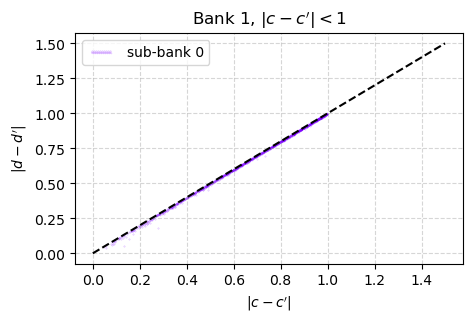

In [24]:
fig=plt.figure()
ax = fig.add_subplot()
#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    color = cm.rainbow(np.linspace(0, 1, subbanks[0]))[i]
    mask_help_plot=pairwise_distances_original_[i][0]<1
    ax.scatter(pairwise_distances_original_[i][0].detach().numpy()[mask_help_plot], 
               pairwise_distances_encoded_[i][0].detach().numpy()[mask_help_plot], 
               alpha=0.3, s=0.1, label="sub-bank "+str(i), color=color)
ax.plot([0,1.5],[0,1.5],'--',c='k')
ax.set_title('Bank '+str(bank_name)+', $|c-c^\\prime|<1$')
ax.set_xlabel('$|c-c^\\prime|$'); ax.set_ylabel('$|d-d^\\prime|$');
ax.legend(loc='upper left',scatterpoints=30)

In [25]:
#--> grid the c^A to mimic a grid...
cos_exp_f1_autoencoder_ungridded=[]
cos_exp_f1_ungridded=[]
cos_exp_f1=[]
cos_exp_f1_autoencoder=[]
cos_exp_f1_autoencoder_gridded=[]

#for i in range(subbanks[0]):
for i in range(1):
    #--> test only b_1_sb_0...
    autoencoder_i = auto_list[i]
    valid_data_i = valid_data[i]
    ind_i=ind[i]
    phases=ca_phases_Vph_mean_phase[i][1]
    Vph=ca_phases_Vph_mean_phase[i][2]
    mean_phase=ca_phases_Vph_mean_phase[i][3]
    norm_factor_ = norm_factor[i]
    ca=ca_phases_Vph_mean_phase[i][0]
    
    ca_autoencoder = autoencoder_i(valid_data_i[:, :dims])[0] * norm_factor_
    ca_autoencoder = ca_autoencoder.detach().numpy() 
    #ca_autoencoder = np.hstack((ca_autoencoder, np.zeros((ca_autoencoder.shape[0], 1000-dims))))
    #--> not needed since now Vph is only the first 10 already...
    phases_f= ca_autoencoder @ Vph + mean_phase
    cos_exp_f1_autoencoder_ungridded.append(np.real(np.einsum('ij,ij -> i', np.exp(1j*phases_f/wt)*wt, np.conj(np.exp(1j*phases[ind_i]/wt)*wt))))

    ca2_ungridded=ca.copy()
    ca2_ungridded[:,3:]=0
    #ca2=np.rint(ca2*8)/8. # Gridding
    phases_f= ca2_ungridded @ Vph + mean_phase #--> no need to pad or play with Vph, I just set to zero everything but the first three...
    cos_exp_f1_ungridded.append(np.real(np.einsum('ij,ij -> i', np.exp(1j*phases_f[ind_i]/wt)*wt, np.conj(np.exp(1j*phases[ind_i]/wt)*wt))))

    ca2=ca.copy()
    ca2[:,3:]=0
    ca2=np.rint(ca2*8)/8. # Gridding
    phases_f= ca2 @ Vph + mean_phase #--> no need to pad or play with Vph, I just set to zero everything but the first three...
    cos_exp_f1.append(np.real(np.einsum('ij,ij -> i', np.exp(1j*phases_f[ind_i]/wt)*wt, np.conj(np.exp(1j*phases[ind_i]/wt)*wt))))

    ca_autoencoder = autoencoder_i(valid_data_i[:, :dims])[0] * norm_factor_
    ca_autoencoder = ca_autoencoder.detach().numpy()
    #--> np.rint the decoded ones...
    #ca_autoencoder = np.hstack((ca_autoencoder, np.zeros((ca_autoencoder.shape[0], 1000-dims))))
    #--> not needed since now Vph is only the first 10 already...
    ca_autoencoder = np.rint(ca_autoencoder*8)/8.
    ca_autoencoder_help=ca_autoencoder.copy()
    phases_f= ca_autoencoder @ Vph + mean_phase
    cos_exp_f1_autoencoder.append(np.real(np.einsum('ij,ij -> i', np.exp(1j*phases_f/wt)*wt, np.conj(np.exp(1j*phases[ind_i]/wt)*wt))))
    #--> here I np.rint the validation ca, and feed them to the autoencoder...
    data_gridded_temp = torch.tensor(np.rint(ca[ind_i, :dims]*8)/8., dtype=torch.float32)
    data_gridded = data_gridded_temp/norm_factor_
    ca_autoencoder = autoencoder_i(data_gridded)[0] * norm_factor_
    ca_autoencoder = ca_autoencoder.detach().numpy()
    #ca_autoencoder = np.hstack((ca_autoencoder, np.zeros((ca_autoencoder.shape[0], 1000-dims))))
    #--> not needed since now Vph is only the first 10 already...
    phases_f= ca_autoencoder @ Vph + mean_phase
    cos_exp_f1_autoencoder_gridded.append(np.real(np.einsum('ij,ij -> i', np.exp(1j*phases_f/wt)*wt, np.conj(np.exp(1j*phases[ind_i]/wt)*wt)))) 

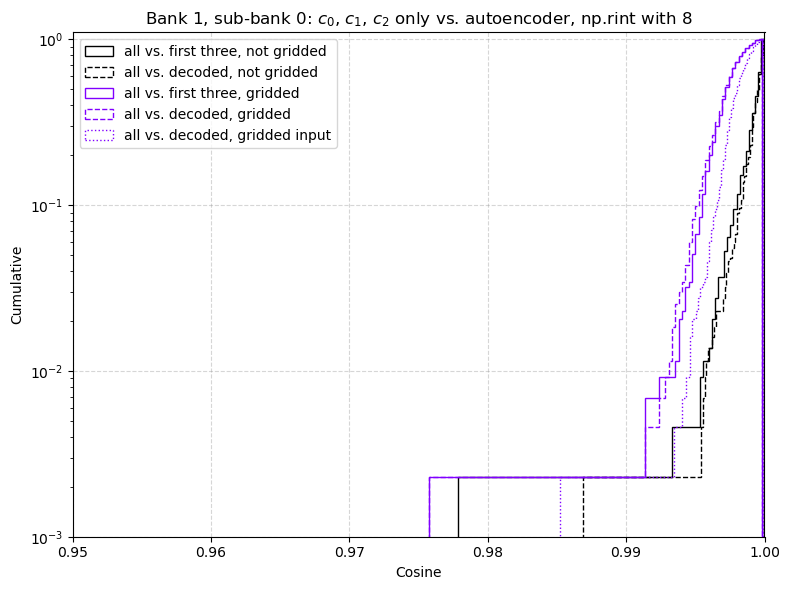

In [26]:
#fig, axes = plt.subplots(subbanks[0], 1, figsize=(10, 25), sharex=True)
fig, axes = plt.subplots(1, 1, figsize=(8, 6), sharex=True)

#color = cm.rainbow(np.linspace(0, 1, subbanks[0]))
color = cm.rainbow(np.linspace(0, 1, 1))

ax = axes
i=0

isb_ = i  # Sub-bank index

# Ungridded
ax.hist(cos_exp_f1_ungridded[isb_], bins=100, density=True, histtype='step',
            cumulative=True, color="k", label="all vs. first three, not gridded")
ax.hist(cos_exp_f1_autoencoder_ungridded[isb_], bins=100, density=True, histtype='step',
            cumulative=True, color="k", linestyle='dashed', label="all vs. decoded, not gridded")

# Gridded
ax.hist(cos_exp_f1[isb_], bins=100, density=True, histtype='step',
            cumulative=True, color=color[0], label="all vs. first three, gridded")
ax.hist(cos_exp_f1_autoencoder[isb_], bins=100, density=True, histtype='step',
            cumulative=True, color=color[0], linestyle='dashed', label="all vs. decoded, gridded")
ax.hist(cos_exp_f1_autoencoder_gridded[isb_], bins=100, density=True, histtype='step',
            cumulative=True, color=color[0], linestyle='dotted', label="all vs. decoded, gridded input")

ax.set_yscale('log')
ax.set_ylim(0.001, 1.1)
ax.set_xlim(0.95, 1)
ax.set_xlabel('Cosine')
ax.set_ylabel('Cumulative')
ax.set_title(f'Bank '+str(bank_name)+', sub-bank '+str(i)+': $c_0$, $c_1$, $c_2$ only vs. autoencoder, np.rint with 8')
ax.legend()

plt.tight_layout()